In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('superstore_csv_exp4.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (10194, 21)

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840



Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  o

In [2]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

print("Date Conversion Successful")
print("Earliest Order Date:", df['Order Date'].min())
print("Latest Order Date:", df['Order Date'].max())

Date Conversion Successful
Earliest Order Date: 2023-01-03 00:00:00
Latest Order Date: 2026-12-30 00:00:00


In [3]:
# Reference date: one day after the latest order
reference_date = df['Order Date'].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df.groupby('Customer ID').agg(
    Recency=('Order Date', lambda x: (reference_date - x.max()).days),
    Frequency=('Order ID', 'nunique'),
    Monetary=('Sales', 'sum')
).reset_index()

print("RFM Table:")
display(rfm.head())

print("Total Customers:", len(rfm))

RFM Table:


,Customer ID,Recency,Frequency,Monetary
0,AA-10315,185,5,5563.560
1,AA-10375,20,9,1056.390
2,AA-10480,260,4,1790.512
3,AA-10645,56,6,5086.935
4,AB-10015,416,3,886.156


Total Customers: 804


In [4]:
from sklearn.preprocessing import StandardScaler

features = rfm[['Recency', 'Frequency', 'Monetary']]

scaler = StandardScaler()
scaled = scaler.fit_transform(features)

print("RFM Scaling Completed")
print(scaled[:5])

RFM Scaling Completed
[[ 0.20483517 -0.5132388   1.00668631]
 [-0.6849593   0.99138835 -0.69276812]
 [ 0.6092872  -0.88939559 -0.41596319]
 [-0.49082232 -0.13708201  0.82697211]
 [ 1.45054742 -1.26555237 -0.75695583]]


In [5]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Segment'] = kmeans.fit_predict(scaled)

print("K-Means Clustering Completed")
display(rfm.head(10))

K-Means Clustering Completed


,Customer ID,Recency,Frequency,Monetary,Segment
0,AA-10315,185,5,5563.560,0
1,AA-10375,20,9,1056.390,3
2,AA-10480,260,4,1790.512,0
3,AA-10645,56,6,5086.935,3
4,AB-10015,416,3,886.156,1
5,AB-10060,55,8,7755.620,2
6,AB-10105,42,10,14473.571,2
7,AB-10150,42,5,966.710,0
8,AB-10165,11,10,1215.022,3
9,AB-10255,167,9,914.532,3


In [6]:
summary = rfm.groupby('Segment')[[
    'Recency', 'Frequency', 'Monetary'
]].mean()

summary['Customers'] = rfm.groupby('Segment').size()

summary = summary.round(1)

print("Customer Segment Summary:")
display(summary)

Customer Segment Summary:


,Recency,Frequency,Monetary,Customers
Segment,,,,
0,98.7,4.7,1615.7,340
1,546.1,3.8,1585.0,103
2,113.9,8.6,9449.9,67
3,70.6,8.7,3336.1,294


In [7]:
segment_names = {
    0: 'Occasional / Low-value',
    1: 'At-risk Customers',
    2: 'Loyal High-value Customers',
    3: 'Regular Valuable Customers'
}

rfm['Segment_Name'] = rfm['Segment'].map(segment_names)

print("Customer Segments with Names:")
display(rfm.head(10))

Customer Segments with Names:


,Customer ID,Recency,Frequency,Monetary,Segment,Segment_Name
0,AA-10315,185,5,5563.560,0,Occasional / Low-value
1,AA-10375,20,9,1056.390,3,Regular Valuable Customers
2,AA-10480,260,4,1790.512,0,Occasional / Low-value
3,AA-10645,56,6,5086.935,3,Regular Valuable Customers
4,AB-10015,416,3,886.156,1,At-risk Customers
5,AB-10060,55,8,7755.620,2,Loyal High-value Customers
6,AB-10105,42,10,14473.571,2,Loyal High-value Customers
7,AB-10150,42,5,966.710,0,Occasional / Low-value
8,AB-10165,11,10,1215.022,3,Regular Valuable Customers
9,AB-10255,167,9,914.532,3,Regular Valuable Customers


In [8]:
segment_analysis = rfm.groupby(
    ['Segment', 'Segment_Name']
).agg(
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary=('Monetary', 'mean'),
    Customers=('Customer ID', 'count')
).round(1).reset_index()

display(segment_analysis)

,Segment,Segment_Name,Recency,Frequency,Monetary,Customers
0,0,Occasional / Low-value,98.7,4.7,1615.7,340
1,1,At-risk Customers,546.1,3.8,1585.0,103
2,2,Loyal High-value Customers,113.9,8.6,9449.9,67
3,3,Regular Valuable Customers,70.6,8.7,3336.1,294


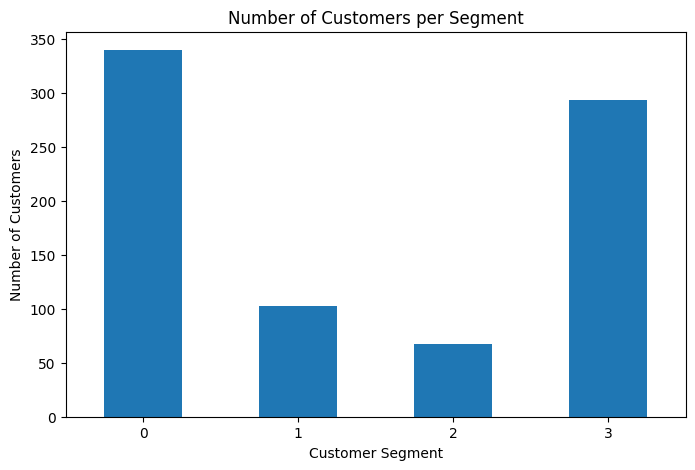

In [9]:
rfm['Segment'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Number of Customers per Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

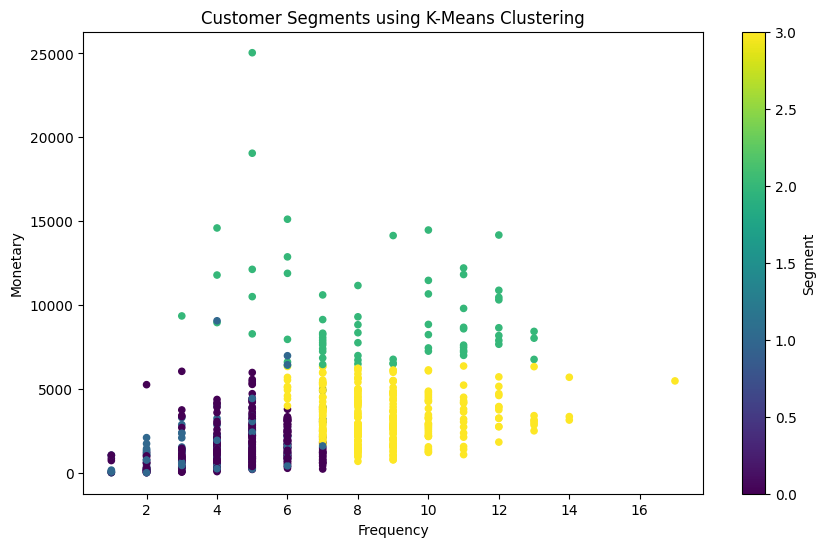

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rfm['Frequency'],
    rfm['Monetary'],
    c=rfm['Segment'],
    cmap='viridis',
    s=20
)

plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.title('Customer Segments using K-Means Clustering')
plt.colorbar(label='Segment')
plt.show()

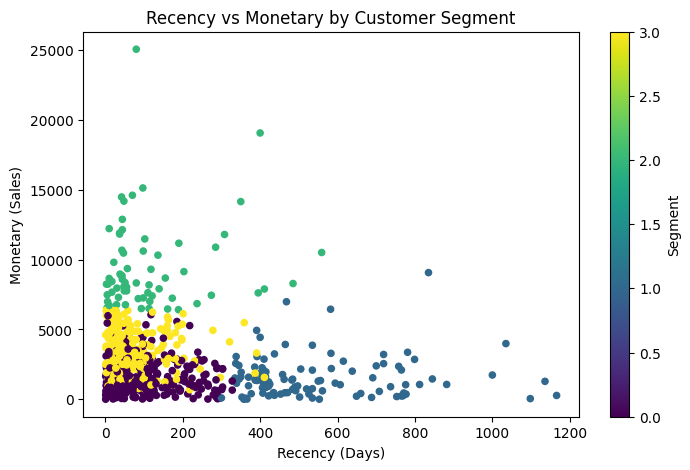

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rfm['Recency'],
    rfm['Monetary'],
    c=rfm['Segment'],
    cmap='viridis',
    s=20
)

plt.xlabel('Recency (Days)')
plt.ylabel('Monetary (Sales)')
plt.title('Recency vs Monetary by Customer Segment')
plt.colorbar(label='Segment')
plt.show()